## **一、这一周为什么从图像走向潜空间**

你已经见过 DDPM 如何学习去噪，也见过 VAE 如何把图像映射成潜变量。本周把两者接起来：先确认压缩后的表示保留任务需要的信息，再让 Transformer 成为潜空间中的噪声预测器。要回答的核心问题是：**数量生成错了，究竟是压缩时已经丢了对象，还是生成主干没有学会？** 如果不先单独检查表示层，后面训练再久，也无法正确解释失败。

本笔记面向熟悉基本 PyTorch、刚完成前两周生成模型入门的读者。建议分三次学习：数据与表示约 3 小时、token 与 DiT 推导约 4 小时、代码与复盘约 3 小时。执行耗时由机器决定，不等于你的学习时间。

本周完整教学实现位于此 Notebook，标记为 `notebook_reference`。项目 `src` 中的 DDPM、VAE、DiT、CFG、Flow 五项个人核心保持待做。后面的短实验只证明明确的数学和工程行为；**本周没有训练完整潜空间扩散生成器，也没有生成能力评测。**

### **1. 三周知识如何连成一条路**

| 已有知识 | 本周承接 | 仍然需要验证的事 |
| --- | --- | --- |
| DDPM：从真实图像构造噪声监督 | 把干净对象从像素 $x$ 换成潜变量 $z$ | 噪声尺度和模型输出是否一致 |
| VAE：编码器给出分布，解码器重建图像 | 使用冻结的空间 Autoencoder，不重新训练它 | 图标的颜色、数量、形状和关系是否保留 |
| Transformer：处理 token 间的关系 | 把二维潜变量切成 patch token | 空间顺序、位置编码和输出重排是否正确 |
| 残差网络：稳定训练深层模型 | 用条件调制和门控组成 DiT Block | 零初始化时哪些梯度应该为零 |

第一周的噪声预测网络是 U-Net；DiT（Diffusion Transformer，扩散 Transformer）改变的是预测网络主干。它不自动改变 DDPM 的加噪公式，也不自带“更少步采样”的保证。本周先学习时间条件，文本条件在 S3 增加。

### **2. 环境、可执行入口与证据边界**

在项目根目录先执行下列准备命令。它们显式安装所需组件、获取公开论文与一份 VAE 权重；Notebook 本身不暗中下载其他模型。权重和真实数据放忽略目录，核心论文保留在 papers。

本笔记由项目 Python 内核执行，HTML 使用第三周独立位置。重跑会重新执行真实 VAE 诊断与最多 100 步教学拟合，不会购买云资源。

In [1]:
# 准备命令（说明文本；在终端执行，不在 Python 内核直接运行）：
# uv sync --locked --extra notebook --extra latent
# uv run --locked --extra notebook --extra latent python scripts/prepare_week3_assets.py
# uv run --locked --extra notebook --extra latent python scripts/execute_learning.py \
#   docs/learning/S2_第3周_图标数据与潜空间DiT基础.ipynb \
#   --html-output artifacts/runs/s2_week3/learning_preview.html
import copy
import json
import math
import os
import platform
import sys
import time as walltime
from pathlib import Path

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "pyproject.toml").exists() and (p / "src/minigen").is_dir()
)
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
os.environ.setdefault("HF_HUB_OFFLINE", "1")
import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from PIL import Image

from minigen.autoencoders.frozen import (
    FrozenVAE,
    cache_identity,
    hash_file,
    image_batch,
    load_cache,
    write_cache,
)
from minigen.data.icons import (
    audit_icons,
    build_icons,
    load_manifest,
    render,
    select_validation,
)
from minigen.evaluation.icons import aggregate_scores, gate_passes, score_image
from minigen.evaluation.latent import encode_pilot, fit_fixed_target, reconstruct

torch.set_num_threads(4)
torch.manual_seed(20261028)
np.random.seed(20261028)
RUN = ROOT / "artifacts/runs/s2_week3"
FIG = ROOT / "reports/stage2/figures/week3"
RUN.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
DEVICE = "cpu"
if torch.backends.mps.is_available():
    try:
        probe = torch.ones(4, device="mps", requires_grad=True)
        probe.square().sum().backward()
        torch.mps.synchronize()
        DEVICE = "mps"
    except RuntimeError as error:
        print("MPS probe failed, using CPU:", error)
print(
    {
        "root": str(ROOT),
        "python": sys.version.split()[0],
        "interpreter": sys.executable,
        "torch": torch.__version__,
        "device": DEVICE,
        "machine": platform.machine(),
    }
)

{'root': '/Users/lucius/projects/personal/MiniGen', 'python': '3.12.14', 'interpreter': '/Users/lucius/projects/personal/MiniGen/.venv/bin/python', 'torch': '2.14.1', 'device': 'mps', 'machine': 'arm64'}


## **二、先理解完整系统，再进入局部公式**

### **1. 训练与生成走不同的路**

训练时我们拥有真实图像 $x$。冻结编码器把 $x$ 变成干净潜变量 $z$，程序抽取时间 $t$ 与标准高斯噪声 $\epsilon$，构造 $z_t$。DiT 观察 $z_t$ 和时间，输出噪声估计 $\epsilon_\theta$；均方误差告诉它哪里预测错了。反向传播只更新 DiT，冻结 VAE 无需保存梯度。

**训练数据流**：真实图像 → 规范化 → 编码 → 缩放后的 $z$ → 在随机时间加噪 → DiT → 噪声 MSE → 更新 DiT。

生成时没有真实图像可编码。先从高斯分布抽取初始潜变量，采样器反复调用 DiT 更新状态，直到得到干净潜变量估计，再逆缩放交给解码器。

**生成数据流**：高斯噪声 → 多次调用 DiT 与采样器 → 干净潜变量估计 → 逆缩放 → 解码 → 图像。

冻结编码器和解码器提供表示；DiT 提供对数据分布的去噪知识；采样器决定怎样沿噪声时间更新。解码器能输出图像，不代表输入它的随机潜变量来自正确的图标分布。

### **2. 简化 VAE 与现代空间 Autoencoder**

第二周的 MLP VAE 将 28×28 灰度图展平，再压成 16 维向量。这个实验便于理解 ELBO、重参数化与 KL；它不是后续潜空间图像系统的同规格替代品。

空间 Autoencoder 保留二维网格。例如，本周 RGB 图像的形状为 $[B,3,128,128]$，编码后是 $[B,4,16,16]$。每个空间位置仍与图像区域有关，适合 patch 化。压缩率不能只看通道：像素标量数为 $3\times128\times128=49152$，潜变量标量数为 $4\times16\times16=1024$，这里减少约 48 倍；空间边长只减少 8 倍。

现代感知 Autoencoder 的训练可能包含重建、感知、正则及对抗目标；第二周的灰度 soft-target BCE 不能概括这些目标。本周直接使用预训练组件，研究它在图标任务上的实际信息保留，不宣称复现了其预训练。

### **3. 训练目标和质量指标回答不同问题**

像素 MSE 衡量数值偏差；颜色、形状、数量和位置指标衡量任务属性。一个白底图标中背景占比很大，整张图 MSE 可能很低，而一个小对象已消失。相反，颜色边缘出现少量重建误差，MSE 上升，但对象数量与关系仍然正确。

因此我们先检查原图能否被解析，再比较重建；解析失败始终计入分母。规则解析器只是本周诊断工具，生成图的畸形、混色与歧义更复杂，S3 仍需单独验证评测器。

## **三、受控图标：让数据本身能回答研究问题**

### **1. 一个样本需要记录什么**

一个样本不只是 PNG。它还需要来源版本、唯一标识、相对路径、文件哈希、描述、结构化对象、关系、场景组和划分。描述由真实场景属性生成，避免 AI 猜测标签。对象的颜色与形状组合在同图内唯一，例如“红圆”不会同时指代两个对象。

数据采用白底、圆/方/三角形、四种颜色、1–3 个对象，最小外接框边长 24 像素，框之间至少相隔 8 像素。生成器先抽离散布局与属性，再用场景组哈希分配集合，最后渲染尺寸和小位置扰动。同一场景组的近似变体不会跨集合。

| 划分 | 数量 | 研究用途 |
| --- | --- | --- |
| train | 10000 | 以后训练生成主干 |
| validation | 1000 | 本周表示诊断，以后选择超参数 |
| test_id | 1000 | 冻结选型后的分布内评价 |
| test_combo | 1000 | 含训练未见的红三角或蓝方形 |
| test_template | 1000 | 已见视觉组合，未见描述模板 |

本周不训练文本模型，组合外和模板外划分先建立并冻结。检查划分合法性可以读取元数据；不能把测试重建结果用于修改对象尺寸或选择参数。

### **2. 可复现生成、划分与质量报告**

In [2]:
config = yaml.safe_load((ROOT / "configs/datasets/icons_week3.yaml").read_text())
manifest_path = build_icons(config, ROOT / "data")
records = load_manifest(manifest_path, ROOT / "data", verify_hashes=True)
data_audit = audit_icons(records, ROOT / "data")
assert data_audit["counts"] == config["split_counts"]
assert data_audit["unique_pixels"] == 14000
assert data_audit["min_object_size"] >= 24 and data_audit["min_bbox_gap"] >= 8
print(
    {
        k: v
        for k, v in data_audit.items()
        if k not in {"distribution", "cross_split_thumbnail_candidates"}
    }
)
example = next(r for r in records if r["split"] == "train" and r["attributes"]["count"] == 3)
print(
    json.dumps(
        {k: example[k] for k in ["sample_id", "caption", "group_id", "attributes"]},
        ensure_ascii=False,
        indent=2,
    )
)

{'counts': {'test_template': 1000, 'train': 10000, 'test_combo': 1000, 'test_id': 1000, 'validation': 1000}, 'generation_sampling': {'candidates': 26072, 'accepted': 14000, 'rejected': 12072, 'rejection_reasons': ['out_of_bounds_or_insufficient_gap', 'split_quota_filled', 'object_count_quota_filled', 'duplicate_pixels'], 'per_reason_counts': 'not_instrumented'}, 'unique_pixels': 14000, 'groups': 7318, 'min_object_size': 24, 'min_bbox_gap': 8.0, 'cross_split_thumbnail_candidate_groups': 0, 'near_duplicate_method': '16x16 RGB BOX thumbnail, 3-bit/channel bucket equality', 'near_duplicate_limit': 'Candidate screen only; not an exhaustive perceptual guarantee', 'total_png_bytes': 7244694}
{
  "sample_id": "synthetic_icons_week3_v1-train-00000",
  "caption": "On a white background: a green triangle, a red circle, a green square. Positions: the red circle is left of the green triangle; the green triangle is above the red circle; the green triangle is left of the green square; the green trian

上面的生成入口在发现同版本数据时先校验哈希，不静默覆盖。如果配置变化，必须使用新数据版本。文件完全重复、场景组跨集合和不符合组合隔离规则会直接报错。近似检查使用 16×16 RGB 缩略图量化桶筛候选，它能发现一部分相近内容，但不是穷尽的感知重复证明。

数据只有约几 MB 时，仍然需要完整记录。数据治理的价值在于解释和复现错误，并不由数据量大不大决定。

### **3. 看见数据的分布和描述**

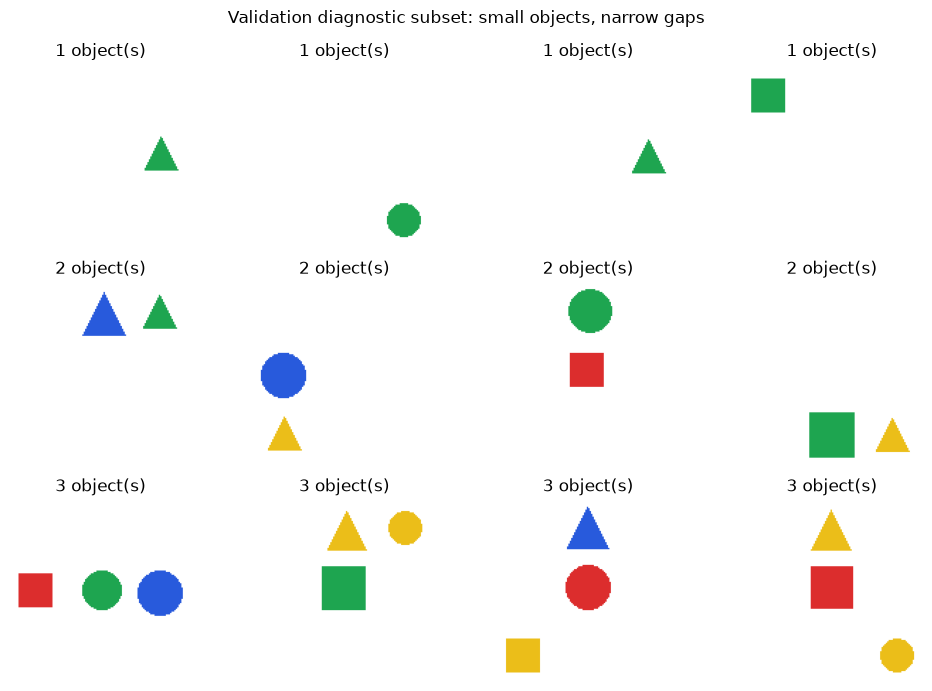

All 96 diagnostic examples are from validation: {'validation'}


In [3]:
selected = select_validation(records, 96)
fig, axes = plt.subplots(3, 4, figsize=(10, 7))
for ax, row in zip(axes.flat, [selected[i] for i in [0, 1, 2, 3, 32, 33, 34, 35, 64, 65, 66, 67]]):
    with Image.open(ROOT / "data" / row["image_path"]) as image:
        ax.imshow(image)
    ax.set_title(f"{row['attributes']['count']} object(s)")
    ax.axis("off")
fig.suptitle("Validation diagnostic subset: small objects, narrow gaps")
fig.tight_layout()
fig.savefig(FIG / "icons.png", dpi=140)
plt.show()
print("All 96 diagnostic examples are from validation:", {r["split"] for r in selected})

### **4. 原图与人为失败检查解析器**

解析器先把像素匹配到颜色原型，再找连通区域，最后用前景面积占外接框的比例区分形状。理想方形接近 1，圆接近 $\pi/4\approx0.785$，直立三角形接近 $1/2$。这是针对本项目规则图标的假设，不适用于任意插画。

对象匹配先依据位置寻找对应，再比较颜色与形状，不能先按正确属性匹配从而掩盖绑定错误。数量不一致时，本图的属性和关系命中按失败处理。下一单元检查原图，以及删对象、改颜色和空白图三类已知错误。

Raw full dataset: {'images': 14000, 'count_accuracy': 1.0, 'color_accuracy': 1.0, 'shape_accuracy': 1.0, 'relation_accuracy': 1.0, 'all_accuracy': 1.0, 'parse_failure_rate': 0.0, 'object_denominator': 27995, 'relation_denominator': 28028}
Known corruptions (must fail): [{'count_correct': 0, 'color_hits': 0, 'shape_hits': 0, 'object_total': 3, 'relation_hits': 0, 'relation_total': 3, 'all_correct': 0, 'parse_failure': 0}, {'count_correct': 1, 'color_hits': 2, 'shape_hits': 3, 'object_total': 3, 'relation_hits': 3, 'relation_total': 3, 'all_correct': 0, 'parse_failure': 0}, {'count_correct': 0, 'color_hits': 0, 'shape_hits': 0, 'object_total': 3, 'relation_hits': 0, 'relation_total': 3, 'all_correct': 0, 'parse_failure': 1}]


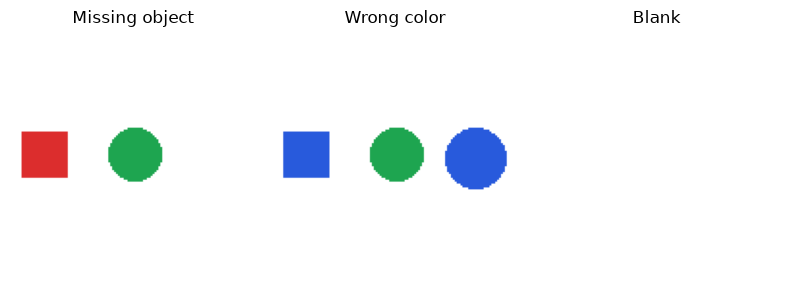

In [4]:
raw_scores = []
for row in records:
    with Image.open(ROOT / "data" / row["image_path"]) as image:
        raw_scores.append(score_image(image, row))
raw_metrics = aggregate_scores(raw_scores)
assert raw_metrics["all_accuracy"] == 1
row = next(r for r in selected if r["attributes"]["count"] == 3)
objects = copy.deepcopy(row["attributes"]["objects"])
recolored = copy.deepcopy(objects)
recolored[0]["color"] = "blue" if recolored[0]["color"] != "blue" else "red"
bad_images = [render(objects[:-1]), render(recolored), Image.new("RGB", (128, 128), "white")]
degraded_metrics = [score_image(image, row) for image in bad_images]
assert all(m["all_correct"] == 0 for m in degraded_metrics)
print("Raw full dataset:", raw_metrics)
print("Known corruptions (must fail):", degraded_metrics)
fig, axes = plt.subplots(1, 3, figsize=(8, 3))
for ax, image, label in zip(axes, bad_images, ["Missing object", "Wrong color", "Blank"]):
    ax.imshow(image)
    ax.set_title(label)
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG / "parser_failures.png", dpi=140)
plt.show()

## **四、冻结 VAE：压缩、概率与缩放必须分清**

### **1. 后验均值与随机样本不是同一个对象**

设图像为 $x$，编码器参数为 $\phi$。对角高斯近似后验为：

$$q_\phi(h\mid x)=\mathcal N\big(h;\mu_\phi(x),\operatorname{diag}(\sigma_\phi^2(x))\big)$$

用 $h$ 表示编码器原始潜变量，避免与缩放后的 $z$ 混淆。随机编码使用 $h=\mu+\sigma\odot\eta$，其中 $\eta\sim\mathcal N(0,I)$；本项目缓存选择固定后验均值 $h=\mu$。在高斯分布中，均值与众数相同，所以 `.mode()` 返回它。

固定均值减少每次编码带来的随机变化，便于受控比较；这是一项工程配方选择，不能说它与论文的随机后验采样完全等价。后续两种训练配方必须使用同一种编码策略。

第二周的 KL 正则使近似后验受到先验约束，但不能据此推出本任务缓存潜变量的经验均值精确为 0、方差精确为 1。尤其是这里选取后验均值，少了后验采样方差。

### **2. 编码、缩放和解码的完整关系**

设模型配置给定正缩放常数 $s$。送入生成主干的变量定义为 $z=sh$。生成完成后，解码器需要原始尺度的 $h$，因此必须逆变换：

$$z=s\mu_\phi(x),\qquad \hat x=D_\psi\left(\frac{z}{s}\right)$$

把 $z=s\mu$ 代回解码可得 $\hat x=D_\psi(\mu)$。这证明缩放在正确配对时不会额外改变原来的 VAE 重建。如果忘记除以 $s$，就会把错误分布的输入交给解码器。

空间下采样由网络结构决定；这个常数只改变数值尺度，不改变 $[B,C,H,W]$ 的维度。也不要用本数据实测标准差随意替换模型配置，否则会产生一种新的、必须单独验证的训练配方。

> 数值例：若 $h=2$，$s=0.13025$，则 $z=0.2605$；逆缩放 $0.2605/0.13025=2$。若误用另一个 VAE 的系数 $0.18215$，恢复值约为 $1.43014$，已经偏离输入。

In [5]:
scale_example = 0.13025
scaled = 2.0 * scale_example
print(
    {
        "h": 2.0,
        "z": scaled,
        "correct_inverse": scaled / scale_example,
        "wrong_inverse": scaled / 0.18215,
    }
)
assert math.isclose(scaled / scale_example, 2.0)

{'h': 2.0, 'z': 0.2605, 'correct_inverse': 2.0, 'wrong_inverse': 1.4301399945100193}


### **3. 明确图像范围与冻结边界**

PNG 是 0–255 的 RGB。此 VAE 接收浮点 $[-1,1]$：$x=\mathrm{RGB}/127.5-1$。第二周简化 VAE 使用 $[0,1]$，因为其教学 BCE 与 sigmoid 输出采取不同约定；不能全项目替换像素范围。

冻结由 `eval()`、`requires_grad_(False)` 和无梯度编码/解码共同落实。编码的数值、缩放、模型文件哈希及后验模式都进入缓存身份。下列代码只读取此前显式准备的本地权重；不加载完整 SDXL、文本编码器或生成主干。

In [6]:
# VAE + cache + fit 的计算上限；先前短跑耗时也计入预算。
preflight_path = RUN / "preflight_reconstruction.json"
preflight_seconds = (
    json.loads(preflight_path.read_text())["seconds"] if preflight_path.exists() else 0
)
prior_path = RUN / "extra_compute_seconds.json"
prior_seconds = (
    json.loads(prior_path.read_text())["prior_notebook_seconds"] if prior_path.exists() else 0
)
experiment_start = walltime.monotonic()
deadline = experiment_start + max(0, 1800 - preflight_seconds - prior_seconds)
adapter = FrozenVAE.load(ROOT, ROOT / "configs/models/sdxl_vae.json", DEVICE)
print(
    {
        "revision": adapter.identity["revision"],
        "scale": adapter.scale,
        "parameter_count": sum(p.numel() for p in adapter.model.parameters()),
        "trainable": sum(p.numel() for p in adapter.model.parameters() if p.requires_grad),
        "preflight_seconds_already_used": preflight_seconds,
    }
)
assert not adapter.model.training
assert all(not p.requires_grad for p in adapter.model.parameters())

/Users/lucius/projects/personal/MiniGen/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'revision': '207b116dae70ace3637169f1ddd2434b91b3a8cd', 'scale': 0.13025, 'parameter_count': 83653863, 'trainable': 0, 'preflight_seconds_already_used': 64.06435287499335}


## **五、真实表示实验：先定位重建，再讨论生成**

### **1. 预先固定门槛与诊断样本**

固定验证子集为 96 张：1、2、3 个对象各 32 张，优先覆盖小尺寸与窄间距。这个选择是有意的压力检查，不是整个分布的无偏质量估计。正式测试集不参与本周选型。

门槛先于结果确定：原图解析全部正确；重建颜色与形状准确率至少 98%；数量、关系和全部属性同时正确比例至少 95%。每项分母分别是对象、关系或图像数，必须一起公开；解析失败不能删除。

若门槛未过，先对照图片检查解析器。确认表示能力或尺寸问题后，使用新版本把最小对象和间距提高到 32、12 像素，复验一次。不能仅为了过门槛调低阈值。本笔记的代码会清楚显示未通过，并跳过正式试点缓存冻结；仍可完成不依赖真实缓存的形状与数学教学。

In [7]:
z_validation, reconstructed, reconstruction_metrics = reconstruct(
    adapter, selected, ROOT / "data", deadline, batch_size=4
)
representation_passed = (
    reconstruction_metrics["completed"] == 96
    and reconstruction_metrics["original"]["all_accuracy"] == 1
    and gate_passes(reconstruction_metrics["reconstruction"])
)
print({k: v for k, v in reconstruction_metrics.items() if k not in {"per_image", "sample_ids"}})
print("Representation gate:", representation_passed)

VAE reconstruction 16/96


VAE reconstruction 32/96


VAE reconstruction 48/96


VAE reconstruction 64/96


VAE reconstruction 80/96


VAE reconstruction 96/96


{'requested': 96, 'completed': 96, 'stop_reason': 'complete', 'seconds': 6.289969916921109, 'original': {'images': 96, 'count_accuracy': 1.0, 'color_accuracy': 1.0, 'shape_accuracy': 1.0, 'relation_accuracy': 1.0, 'all_accuracy': 1.0, 'parse_failure_rate': 0.0, 'object_denominator': 192, 'relation_denominator': 185}, 'reconstruction': {'images': 96, 'count_accuracy': 1.0, 'color_accuracy': 1.0, 'shape_accuracy': 1.0, 'relation_accuracy': 1.0, 'all_accuracy': 1.0, 'parse_failure_rate': 0.0, 'object_denominator': 192, 'relation_denominator': 185}, 'pixel_mse_raw_minus1_to1': 0.0011038156312679348, 'pixel_mse_clipping': False, 'latent_shape': [96, 4, 16, 16], 'latent_channel_mean': [2.236180305480957, 0.16181473433971405, 0.9333890080451965, -0.8128278851509094], 'latent_channel_std': [0.7447116374969482, 0.5620944499969482, 0.6559074521064758, 0.5086426138877869], 'latent_abs_max': 4.453760147094727}
Representation gate: True


### **2. 逐图观察：原图、重建、误差**

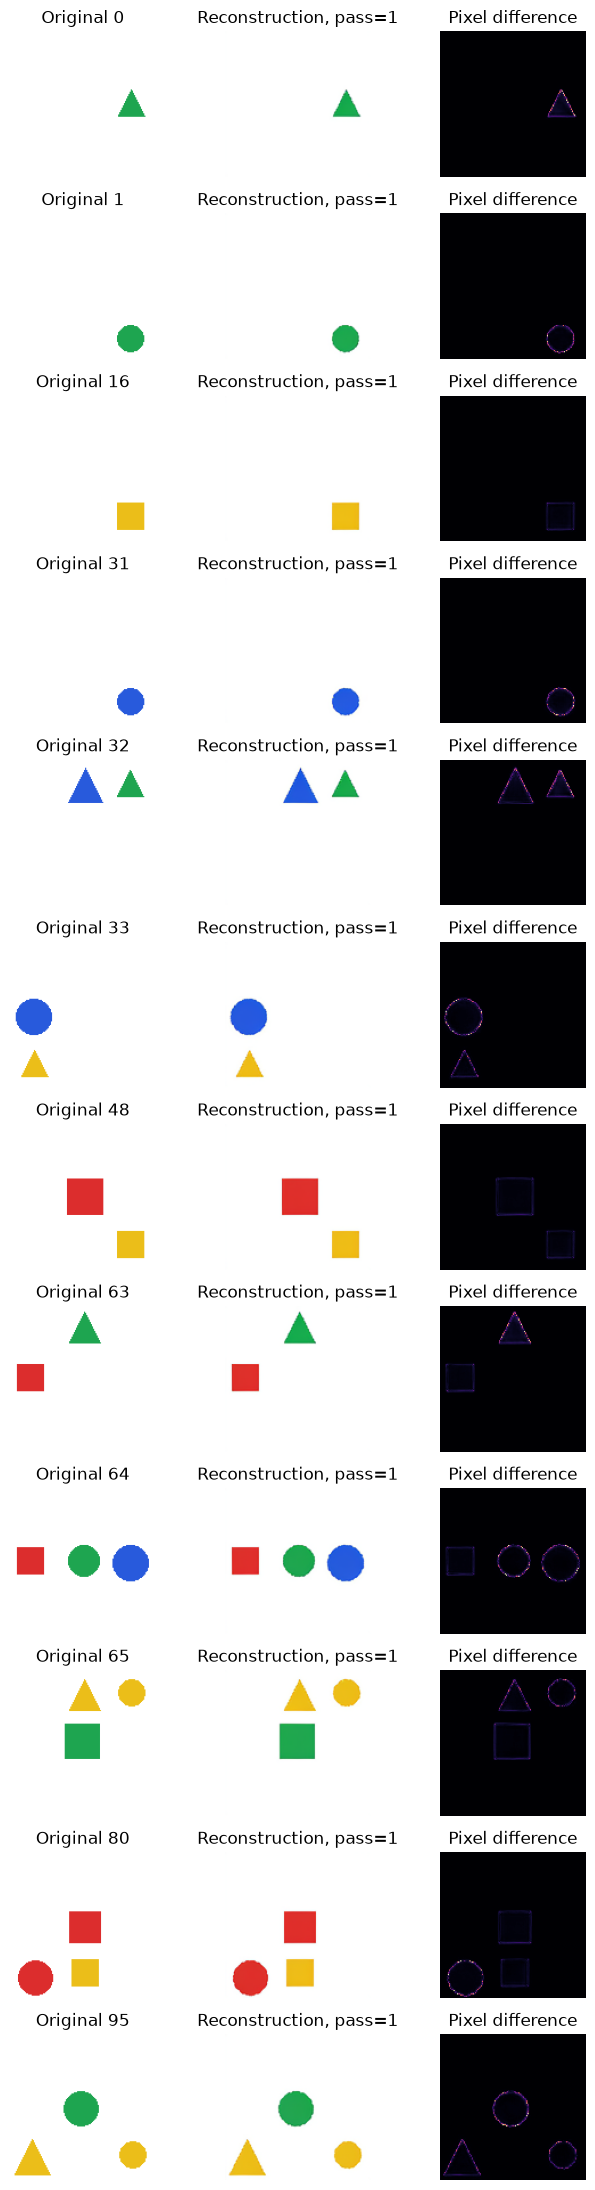

In [8]:
show_indices = [0, 1, 16, 31, 32, 33, 48, 63, 64, 65, 80, 95]
fig, axes = plt.subplots(len(show_indices), 3, figsize=(7, 22))
for axes_row, i in zip(axes, show_indices):
    if i >= len(reconstructed):
        for ax in axes_row:
            ax.axis("off")
        continue
    with Image.open(ROOT / "data" / selected[i]["image_path"]) as image:
        original = image.copy()
    axes_row[0].imshow(original)
    axes_row[1].imshow(reconstructed[i])
    error = np.abs(
        np.asarray(original).astype(float) - np.asarray(reconstructed[i]).astype(float)
    ).mean(-1)
    axes_row[2].imshow(error, cmap="magma", vmin=0, vmax=100)
    for ax in axes_row:
        ax.axis("off")
    axes_row[0].set_title(f"Original {i}")
    axes_row[1].set_title(
        f"Reconstruction, pass={reconstruction_metrics['per_image'][i]['all_correct']}"
    )
    axes_row[2].set_title("Pixel difference")
fig.tight_layout()
fig.savefig(FIG / "reconstructions.png", dpi=120)
plt.show()

重点看：小三角的尖端是否变钝、相邻对象是否粘连、黄色是否发生颜色偏移、对象中心是否跨过关系边界。像素差图会放大边缘误差，但应与属性结果共同解释。

这张对照板只展示预先选定的 12 个案例，不替代 96 张的全部指标。逐图指标及标识保存在结构化报告中。视觉检查由 Agent 执行，不能冒充学习者已完成人工理解验收。

### **3. 潜变量统计与缩放往返验证**

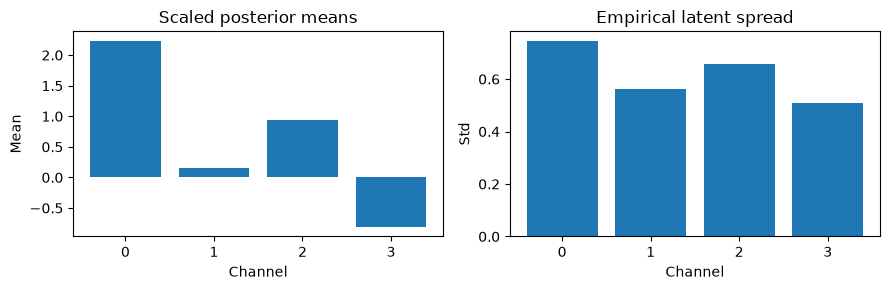

{'inverse_scale_max_abs': 9.5367431640625e-07, 'decode_path_max_abs': 6.9141387939453125e-06}


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].bar(range(4), reconstruction_metrics["latent_channel_mean"])
axes[0].set(title="Scaled posterior means", xlabel="Channel", ylabel="Mean")
axes[1].bar(range(4), reconstruction_metrics["latent_channel_std"])
axes[1].set(title="Empirical latent spread", xlabel="Channel", ylabel="Std")
fig.tight_layout()
fig.savefig(FIG / "latent_statistics.png", dpi=140)
plt.show()
small_images = image_batch(selected[:2], ROOT / "data")
with torch.no_grad():
    raw_mean = adapter.model.encode(small_images.to(DEVICE)).latent_dist.mode()
    scaled_mean = adapter.encode(small_images)
    direct_decode = adapter.model.decode(raw_mean).sample
    adapter_decode = adapter.decode(scaled_mean)
scale_error = (scaled_mean / adapter.scale - raw_mean).abs().max().item()
decode_error = (adapter_decode - direct_decode).abs().max().item()
torch.testing.assert_close(scaled_mean / adapter.scale, raw_mean, rtol=1e-5, atol=1e-6)
torch.testing.assert_close(adapter_decode, direct_decode, rtol=1e-4, atol=1e-4)
print({"inverse_scale_max_abs": scale_error, "decode_path_max_abs": decode_error})

## **六、缓存：让实验共享同一个表示世界**

### **1. 缓存为什么需要身份，而不只是文件名**

缓存把昂贵的冻结编码移出主干训练循环，减少重复计算。但若图片、描述、预处理或权重变了，旧缓存不一定继续有效。文件名相同不代表内容相同。

本周缓存身份包括：完整数据清单指纹、每个样本的图像哈希、编码器 revision 和文件哈希、后验均值策略、像素预处理、缩放及 dtype。没有文本特征缓存，所以描述版本通过清单指纹一起约束；未来文本缓存另建身份。

只建立 256 张训练图像的试点。它验证格式、顺序和失效检查，不等同于完成 14000 张的全量缓存任务。Numpy 文件禁用 pickle 加载，元数据还记录 payload 哈希以发现损坏。

In [10]:
pilot_metrics = {"status": "not_frozen", "reason": "representation_gate_failed_or_incomplete"}
pilot_latents = None
if representation_passed:
    pilot_rows = [r for r in records if r["split"] == "train"][:256]
    pilot_latents, pilot_metrics = encode_pilot(adapter, pilot_rows, ROOT / "data", deadline)
    completed_rows = pilot_rows[: len(pilot_latents)]
    identity = cache_identity(adapter, completed_rows, hash_file(manifest_path))
    cache_path = ROOT / "artifacts/cache/s2_week3/pilot_latents.npy"
    if len(pilot_latents) == 256:
        write_cache(cache_path, pilot_latents, identity)
        torch.testing.assert_close(load_cache(cache_path, identity), pilot_latents, rtol=0, atol=0)
        single = adapter.encode(image_batch(completed_rows[:1], ROOT / "data")).cpu()
        batch_single_error = (single[0] - pilot_latents[0]).abs().max().item()
        torch.testing.assert_close(single[0], pilot_latents[0], rtol=2e-4, atol=2e-4)
        rejected = []
        for field in [
            "manifest_sha256",
            "model_revision",
            "scale",
            "preprocessing",
            "encoder_mode",
        ]:
            incompatible = copy.deepcopy(identity)
            incompatible[field] = "CHANGED"
            try:
                load_cache(cache_path, incompatible)
            except ValueError:
                rejected.append(field)
        assert len(rejected) == 5
        pilot_metrics.update(
            status="pilot_frozen",
            batch_single_max_abs=batch_single_error,
            incompatible_fields_rejected=rejected,
        )
print(pilot_metrics)

Pilot encoding 64/256


Pilot encoding 128/256


Pilot encoding 192/256


Pilot encoding 256/256


{'requested': 256, 'completed': 256, 'stop_reason': 'complete', 'seconds': 5.126033290987834, 'status': 'pilot_frozen', 'batch_single_max_abs': 0.0, 'incompatible_fields_rejected': ['manifest_sha256', 'model_revision', 'scale', 'preprocessing', 'encoder_mode']}


### **2. 容量与计算成本的小算例**

每张潜变量为 $4\times16\times16=1024$ 个 FP32 数，载荷为 $1024\times4=4096$ 字节；256 张约 1 MiB，14000 张约 54.7 MiB。这里不包含 JSON 元数据、文本特征和模型权重。

RGB 像素虽然有约 48 倍标量数，但简单图形 PNG 压缩率很高，实际 PNG 甚至可能比 FP32 潜变量更小。因此“缓存压缩表示”主要节省反复编码的计算，不保证压缩后的磁盘文件一定更小。

In [11]:
print(
    {
        "latent_bytes_each": 4 * 16 * 16 * 4,
        "pilot_MiB": 256 * 4 * 16 * 16 * 4 / 2**20,
        "full_MiB_estimate": 14000 * 4 * 16 * 16 * 4 / 2**20,
        "actual_png_MiB": data_audit["total_png_bytes"] / 2**20,
    }
)

{'latent_bytes_each': 4096, 'pilot_MiB': 1.0, 'full_MiB_estimate': 54.6875, 'actual_png_MiB': 6.909078598022461}


## **七、把 DDPM 迁移到潜空间，哪些变了、哪些没变**

### **1. 训练目标仍然是噪声预测**

设固定 VAE 编码得到干净潜变量 $z$。沿用第一周的 $\alpha_t=1-\beta_t$、$\bar\alpha_t=\prod_{i=1}^t\alpha_i$，则：

$$z_t=\sqrt{\bar\alpha_t}z+\sqrt{1-\bar\alpha_t}\epsilon,\qquad\epsilon\sim\mathcal N(0,I)$$

$$L(\theta)=\mathbb E_{z,t,\epsilon}\left[\frac{1}{CHW}\lVert\epsilon_\theta(z_t,t)-\epsilon\rVert_2^2\right]$$

期望对应对数据、时间和噪声的重复抽样；代码再对 batch 求均值。本周不实现另一份 DDPM Scheduler，后续继续由你完成项目核心，再与训练工程连接。

把 $z$ 的位置换成 $x$，就是第一周的像素噪声目标。变化的是数据表示、网络输入通道与空间分辨率；噪声和输出仍然同形状。本项目的输出为 4 通道噪声，不是 RGB，也不是干净图像，更不是 Flow 速度。

训练的最优预测并不意味着网络能知道每一次噪声的唯一来源。给定相同的 $z_t,t$，可能有不同的 $z,\epsilon$ 组合。对固定输入 $v=(z_t,t)$，令预测为 $a$，展开平方误差：

$$\mathbb E[\lVert a-\epsilon\rVert^2\mid v]=\lVert a\rVert^2-2a^\top\mathbb E[\epsilon\mid v]+\mathbb E[\lVert\epsilon\rVert^2\mid v]$$

对 $a$ 求导并令其为零，得到 $a^*=\mathbb E[\epsilon\mid v]$。网络学习的是条件平均去噪信息，而非把每张输入背后的随机数“读出来”。固定样本拟合只能检查它对一组监督信号的记忆与优化。

### **2. 信号、噪声与数值尺度**

对某个潜变量通道，设干净变量经验方差为 $v_z$，噪声与它独立，则：

$$\operatorname{Var}(z_t)=\bar\alpha_t v_z+(1-\bar\alpha_t)$$

干净变量均值不为零时，$\mathbb E[z_t]=\sqrt{\bar\alpha_t}\mathbb E[z]$。只要终点累计信号足够小，这些数据特征才逐渐被标准噪声淹没。因此应记录经验统计，并检查日程终点，而不是看到均值不为零就随意重新归一化。

> 取 $z=2$、$\epsilon=-1$、$\bar\alpha_t=0.64$，则 $z_t=0.8\times2+0.6\times(-1)=1$。若已知真实噪声，恢复为 $(1-0.6\times(-1))/0.8=2$；网络训练前并不知道这个真值。

In [12]:
clean_scalar, noise_scalar, alpha_bar = 2.0, -1.0, 0.64
noisy_scalar = math.sqrt(alpha_bar) * clean_scalar + math.sqrt(1 - alpha_bar) * noise_scalar
recovered_scalar = (noisy_scalar - math.sqrt(1 - alpha_bar) * noise_scalar) / math.sqrt(alpha_bar)
assert math.isclose(noisy_scalar, 1.0) and math.isclose(recovered_scalar, 2.0)
print(
    {
        "z_t": noisy_scalar,
        "oracle_recovery": recovered_scalar,
        "note": "Known-noise algebra, not learned generation",
    }
)

{'z_t': 1.0, 'oracle_recovery': 2.0, 'note': 'Known-noise algebra, not learned generation'}


## **八、从二维潜变量到 token：先把顺序想清楚**

### **1. patchify 的索引与可逆性**

输入 $z\in\mathbb R^{B\times C\times H\times W}$，patch 边长为 $p$，且 $H,W$ 均可被 $p$ 整除。patch 网格为 $H_p=H/p,W_p=W/p$，token 数 $N=H_pW_p$，每个原始 token 宽度为 $K=p^2C$。

先固定顺序：token 从上到下、从左到右；patch 内按行、列、通道排列。令 patch 行列为 $r,s$，内部行为 $i$、列为 $j$、通道为 $c$，则：

$$n=rW_p+s,\qquad k=(ip+j)C+c$$

$$\operatorname{tokens}[b,n,k]=z[b,c,rp+i,sp+j]$$

`unpatchify` 用同一映射的逆过程把数值放回。只做“自己切、自己拼”的往返检查不够：两个函数可能以相同错误顺序互相抵消，仍然通过。因此还要与独立手工排列对照。

原始 patch 向量再经过可学习线性投影 $W_e\in\mathbb R^{K\times D}$，得到隐藏宽度为 $D$ 的 token。这个投影不必可逆；可逆的是尚未投影时的切片与重排。

### **2. 本项目的维度与 token 预算**

对于 $[B,4,16,16]$、$p=2$：$H_p=W_p=8$，$N=64$，$K=16$。投影后得到 $[B,64,256]$。最后每个 token 输出 $p^2C=16$ 个噪声数值，逆排列回 $[B,4,16,16]$。

注意力的每个头会形成 $N\times N$ 的权重矩阵。把 $p=2$ 改成 $p=1$，token 数从 64 变为 256，注意力矩阵元素数增加 16 倍；但线性层计算通常只增加约 4 倍，所以不能把整个模型成本都说成 16 倍。

以一次乘加计数、忽略较小算子，一个含 MLP 扩张比 $r$ 的 Block 约为 $(4+2r)ND^2+2N^2D$。第一部分来自 QKV、输出投影和两层 MLP；第二部分来自 QK 与注意力乘 V。这是数量级分析，不替代硬件实际耗时。

In [13]:
for patch in [1, 2, 4]:
    n, d, ratio = (16 // patch) ** 2, 256, 4
    macs = (4 + 2 * ratio) * n * d * d + 2 * n * n * d
    print(
        {
            "patch": patch,
            "tokens": n,
            "raw_width": patch * patch * 4,
            "attention_entries_per_head": n * n,
            "approx_block_MMAC": macs / 1e6,
        }
    )

{'patch': 1, 'tokens': 256, 'raw_width': 4, 'attention_entries_per_head': 65536, 'approx_block_MMAC': 234.881024}
{'patch': 2, 'tokens': 64, 'raw_width': 16, 'attention_entries_per_head': 4096, 'approx_block_MMAC': 52.4288}
{'patch': 4, 'tokens': 16, 'raw_width': 64, 'attention_entries_per_head': 256, 'approx_block_MMAC': 12.713984}


### **3. 位置与时间是两种不同的条件**

自注意力本身不知道 token 原先位于左上还是右下。二维位置编码为每个网格坐标提供不同向量；本周分别对行、列使用正弦余弦编码，再拼接到隐藏维度，与图像 token 相加。

时间编码表示当前噪声级别：相同的 $z_t$ 数值，在不同时间可能需要不同的去噪解释。先把离散代码时间 $t\in\{0,\ldots,999\}$ 转为多频率正弦余弦特征，再经 MLP 得到 $c\in\mathbb R^{B\times D}$。代码索引 0 对应论文第一次加噪的状态，沿用第一周约定。

一维频率可写为 $\omega_k=\exp(-\log(10000)k/m)$，编码由 $\cos(t\omega_k)$ 与 $\sin(t\omega_k)$ 拼接。位置是空间坐标，时间是噪声级别，两者不能互相替代。

## **九、DiT Block：注意力、调制与门控如何配合**

### **1. 先把普通 Transformer Block 拆开**

输入 $X\in\mathbb R^{B\times N\times D}$。LayerNorm 对每个 token 的特征维度单独计算均值和方差：

$$\mu=\frac1D\sum_dX_d,\qquad v=\frac1D\sum_d(X_d-\mu)^2,\qquad \operatorname{LN}(X)=\frac{X-\mu}{\sqrt{v+\varepsilon_{\mathrm{LN}}}}$$

这里的 $\varepsilon_{\mathrm{LN}}$ 是稳定常数，和扩散噪声 $\epsilon$ 无关。注意力对规范化后的 token 计算 Q、K、V，分成 $n_h$ 个头，每头宽度 $d_h=D/n_h$：

$$Q=XW_Q,\quad K=XW_K,\quad V=XW_V,\qquad A_{ij}=\frac{\exp(Q_iK_j^\top/\sqrt{d_h})}{\sum_l\exp(Q_iK_l^\top/\sqrt{d_h})}$$

$$\operatorname{Attention}(X)=\operatorname{Concat}_{\mathrm{heads}}(AV)W_O$$

每一行注意力权重和为 1，表示一个位置怎样聚合其他位置的信息。MLP 则在每个 token 内做通道变换：先从 $D$ 扩为 $4D$，经 GELU，再回到 $D$。残差连接让输出保留输入并增加变换量。

### **2. adaLN 把时间写入计算过程**

adaLN 是 adaptive Layer Normalization，条件自适应层归一化。它不只是把时间向量加到 token 上，而是由时间条件生成缩放和平移，对规范化后的特征做调制：

$$\operatorname{modulate}(X,c)=\big(1+\gamma(c)\big)\odot\operatorname{LN}(X)+\beta(c)$$

$\gamma,\beta$ 的形状均为 $[B,D]$，扩展为 $[B,1,D]$ 后广播到所有 token；同一图像各位置接收同一噪声时间，而图像内容仍然不同。$1+\gamma$ 使 $\gamma=0,\beta=0$ 时保留原来的 LayerNorm 输出。

> 若 token 为 $(1,2,3,4)$，均值为 2.5，方差为 1.25，规范化后约为 $(-1.342,-0.447,0.447,1.342)$。取 $\gamma=0.2,\beta=-0.1$，第一个值变为 $1.2\times(-1.342)-0.1\approx-1.710$。

In [14]:
x_example = torch.tensor([1.0, 2.0, 3.0, 4.0], dtype=torch.float64)
normalized = (x_example - x_example.mean()) / (x_example.var(unbiased=False) + 1e-6).sqrt()
modulated = normalized * 1.2 - 0.1
print(
    {
        "mean": x_example.mean().item(),
        "variance": x_example.var(unbiased=False).item(),
        "normalized": normalized.tolist(),
        "modulated": modulated.tolist(),
    }
)

{'mean': 2.5, 'variance': 1.25, 'normalized': [-1.3416402498438813, -0.44721341661462705, 0.44721341661462705, 1.3416402498438813], 'modulated': [-1.7099682998126575, -0.6366560999375525, 0.4366560999375525, 1.5099682998126573]}


### **3. adaLN-Zero 为两条残差分支加上门控**

由条件 $c$ 经过 SiLU 和线性层，一次产生六组向量：注意力分支的平移、缩放、门控，以及 MLP 分支的平移、缩放、门控。每组均为 $[B,D]$：

$$[\beta_a,\gamma_a,g_a,\beta_m,\gamma_m,g_m]=W_c\operatorname{SiLU}(c)+b_c$$

$$X'=X+g_a\odot\operatorname{Attention}\big((1+\gamma_a)\odot\operatorname{LN}_1(X)+\beta_a\big)$$

$$X''=X'+g_m\odot\operatorname{MLP}\big((1+\gamma_m)\odot\operatorname{LN}_2(X')+\beta_m\big)$$

零初始化的是条件投影末层的权重和偏置，因此六组向量开始都为零。$g_a=g_m=0$ 时，Block 输出严格等于输入。注意力与 MLP 自身仍使用正常初始化，不是把全模型所有参数都设为零。

官方输出头也初始化为零，因此完整模型初始噪声预测为零；它与“每个 Block 初始为恒等映射”是两个层次的性质。

### **4. 零门控为什么不会永远学不动**

对一条简化残差 $y=x+g f_w(x)$，链式法则给出：

$$\frac{\partial L}{\partial w}=\frac{\partial L}{\partial y}\,g\,\frac{\partial f_w(x)}{\partial w},\qquad \frac{\partial L}{\partial g}=\frac{\partial L}{\partial y}\,f_w(x)$$

当 $g=0$ 时，分支内部参数的梯度可以为零，而门控的梯度通常不为零。门控更新后，梯度才流入分支。完整模型还有零输出头：第一步可能只有输出投影获得梯度；后续门控，再后续分支逐渐得到梯度。因此“所有参数首步梯度都非零”不是正确验收要求。

> 取 $x=2$、分支值 $a=3$、$g=0$，目标为 5，$L=\frac12(y-5)^2$。此时 $y=2$，$\partial L/\partial g=-3\times3=-9$，$\partial L/\partial a=-3\times0=0$。学习率 0.01 更新门控得到 $g=0.09$，下一步分支就有非零梯度。

In [15]:
a = torch.tensor(3.0, requires_grad=True)
g = torch.tensor(0.0, requires_grad=True)
y = 2 + g * a
loss = 0.5 * (y - 5) ** 2
loss.backward()
assert a.grad.item() == 0 and g.grad.item() == -9
print(
    {
        "branch_grad_at_zero": a.grad.item(),
        "gate_grad_at_zero": g.grad.item(),
        "gate_after_update": g.item() - 0.01 * g.grad.item(),
    }
)

{'branch_grad_at_zero': -0.0, 'gate_grad_at_zero': -9.0, 'gate_after_update': 0.09}


## **十、唯一的 DiT 教学参考实现**

### **1. 核心代码与完整张量流**

下面一个代码单元集中定义完整教学核心。为便于逐行理解，注意力显式写出 QKV、缩放点积和 softmax，不依赖外部 DiT 模型。它是依据公式独立编写的教学版本，不宣称与官方模型权重兼容。

`patchify_reference` 给原始 patch；`TeachingDiT` 完成线性投影、二维位置编码、时间条件、多个 Block、输出头和逆排列。默认输出 4 通道噪声。小型诊断模型和主干规格检查共用这一个类，只改变规模配置。

In [16]:
import math

import torch
from torch import nn


def patchify_reference(x, p):
    if x.ndim != 4 or p <= 0 or x.shape[2] % p or x.shape[3] % p:
        raise ValueError("Expected divisible [B,C,H,W] input")
    b, c, h, w = x.shape
    return (
        x.reshape(b, c, h // p, p, w // p, p)
        .permute(0, 2, 4, 3, 5, 1)
        .reshape(b, (h // p) * (w // p), p * p * c)
    )


def unpatchify_reference(tokens, channels, height, width, patch_size):
    p = patch_size
    if p <= 0 or height % p or width % p or tokens.ndim != 3:
        raise ValueError("Invalid target spatial size")
    b, n, k = tokens.shape
    if n != (height // p) * (width // p) or k != p * p * channels:
        raise ValueError("Token count/width mismatch")
    return (
        tokens.reshape(b, height // p, width // p, p, p, channels)
        .permute(0, 5, 1, 3, 2, 4)
        .reshape(b, channels, height, width)
    )


def sincos_1d(values, width):
    if width % 2:
        raise ValueError("Sine/cosine width must be even")
    frequencies = torch.exp(
        -math.log(10000)
        * torch.arange(width // 2, device=values.device, dtype=torch.float32)
        / (width // 2)
    )
    angles = values.float().unsqueeze(-1) * frequencies
    return torch.cat([angles.cos(), angles.sin()], dim=-1)


def position_2d(height, width, hidden):
    if hidden % 4:
        raise ValueError("2D position width must be divisible by four")
    rows, cols = torch.meshgrid(torch.arange(height), torch.arange(width), indexing="ij")
    return torch.cat(
        [sincos_1d(rows.flatten(), hidden // 2), sincos_1d(cols.flatten(), hidden // 2)], dim=-1
    ).unsqueeze(0)


class TeachingAttention(nn.Module):
    def __init__(self, hidden, heads):
        super().__init__()
        if hidden % heads:
            raise ValueError("Hidden dimension must be divisible by heads")
        self.heads, self.head_width = heads, hidden // heads
        self.qkv = nn.Linear(hidden, 3 * hidden)
        self.projection = nn.Linear(hidden, hidden)

    def forward(self, x):
        b, n, d = x.shape
        qkv = self.qkv(x).reshape(b, n, 3, self.heads, self.head_width)
        q, k, v = qkv.permute(2, 0, 3, 1, 4).unbind(0)
        weights = (q @ k.transpose(-2, -1) / math.sqrt(self.head_width)).softmax(-1)
        attended = (weights @ v).transpose(1, 2).reshape(b, n, d)
        return self.projection(attended)


class TeachingDiTBlock(nn.Module):
    def __init__(self, hidden_size=256, num_heads=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(hidden_size, elementwise_affine=False, eps=1e-6)
        self.norm2 = nn.LayerNorm(hidden_size, elementwise_affine=False, eps=1e-6)
        self.attention = TeachingAttention(hidden_size, num_heads)
        self.mlp = nn.Sequential(
            nn.Linear(hidden_size, 4 * hidden_size),
            nn.GELU(approximate="tanh"),
            nn.Linear(4 * hidden_size, hidden_size),
        )
        self.modulation = nn.Sequential(nn.SiLU(), nn.Linear(hidden_size, 6 * hidden_size))
        nn.init.zeros_(self.modulation[-1].weight)
        nn.init.zeros_(self.modulation[-1].bias)

    @staticmethod
    def modulate(x, shift, scale):
        return x * (1 + scale[:, None, :]) + shift[:, None, :]

    def forward(self, tokens, condition):
        if condition.shape != (tokens.shape[0], tokens.shape[-1]):
            raise ValueError("Condition must be [B,D]")
        sa, ca, ga, sm, cm, gm = self.modulation(condition).chunk(6, dim=-1)
        tokens = tokens + ga[:, None, :] * self.attention(self.modulate(self.norm1(tokens), sa, ca))
        return tokens + gm[:, None, :] * self.mlp(self.modulate(self.norm2(tokens), sm, cm))


class TeachingDiT(nn.Module):
    def __init__(self, depth=6, hidden=256, heads=4, channels=4, size=16, patch=2):
        super().__init__()
        if size % patch:
            raise ValueError("Spatial size must divide into patches")
        self.channels, self.size, self.patch = channels, size, patch
        self.patch_projection = nn.Linear(patch * patch * channels, hidden)
        self.register_buffer("position", position_2d(size // patch, size // patch, hidden))
        self.time_mlp = nn.Sequential(
            nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, hidden)
        )
        self.blocks = nn.ModuleList([TeachingDiTBlock(hidden, heads) for _ in range(depth)])
        self.final_norm = nn.LayerNorm(hidden, elementwise_affine=False, eps=1e-6)
        self.final_modulation = nn.Sequential(nn.SiLU(), nn.Linear(hidden, 2 * hidden))
        self.output = nn.Linear(hidden, patch * patch * channels)
        self.hidden = hidden
        self.apply(self._initialize_linear)
        for block in self.blocks:
            nn.init.zeros_(block.modulation[-1].weight)
            nn.init.zeros_(block.modulation[-1].bias)
        nn.init.zeros_(self.final_modulation[-1].weight)
        nn.init.zeros_(self.final_modulation[-1].bias)
        nn.init.zeros_(self.output.weight)
        nn.init.zeros_(self.output.bias)

    @staticmethod
    def _initialize_linear(module):
        if isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight)
            nn.init.zeros_(module.bias)

    def forward(self, z, timesteps):
        if z.shape[1:] != (self.channels, self.size, self.size):
            raise ValueError("Latent shape mismatch")
        if timesteps.shape != (z.shape[0],):
            raise ValueError("Time shape mismatch")
        tokens = self.patch_projection(patchify_reference(z, self.patch)) + self.position
        condition = self.time_mlp(sincos_1d(timesteps, self.hidden))
        for block in self.blocks:
            tokens = block(tokens, condition)
        shift, scale = self.final_modulation(condition).chunk(2, dim=-1)
        outputs = self.output(TeachingDiTBlock.modulate(self.final_norm(tokens), shift, scale))
        return unpatchify_reference(outputs, self.channels, self.size, self.size, self.patch)

逐层对应关系：输入潜变量 $[B,4,16,16]$ → 原始 patch $[B,64,16]$ → 隐藏 token $[B,64,D]$ → 与位置相加 → 时间条件 $[B,D]$ 调制每个 Block → 输出 token $[B,64,16]$ → 4 通道噪声 $[B,4,16,16]$。

官方实现用成熟 patch 投影组件并包含类别条件、可选方差输出等功能。本版本只保留本周需要的时间条件与噪声输出；初始化遵循零调制与零输出思想，其他线性层的统一 Xavier 初始化属于本教学配方，不能据此加载官方权重。

### **2. 独立检查空间顺序，不能只测往返**

In [17]:
example_tensor = torch.arange(16).reshape(1, 2, 2, 4).float()
expected_tokens = torch.tensor([[[0, 8, 1, 9, 4, 12, 5, 13], [2, 10, 3, 11, 6, 14, 7, 15]]]).float()
tokens = patchify_reference(example_tensor, 2)
torch.testing.assert_close(tokens, expected_tokens)
torch.testing.assert_close(unpatchify_reference(tokens, 2, 2, 4, 2), example_tensor)
print("Hand-ordered tokens:", tokens.tolist())
try:
    patchify_reference(torch.zeros(1, 4, 15, 16), 2)
except ValueError as error:
    print("Non-divisible spatial size correctly rejected:", error)
# 非连续内存的输入也必须遵循同一映射。
noncontiguous = torch.randn(2, 3, 8, 12).transpose(-1, -2)
torch.testing.assert_close(
    unpatchify_reference(patchify_reference(noncontiguous, 2), 3, 12, 8, 2), noncontiguous
)

Hand-ordered tokens: [[[0.0, 8.0, 1.0, 9.0, 4.0, 12.0, 5.0, 13.0], [2.0, 10.0, 3.0, 11.0, 6.0, 14.0, 7.0, 15.0]]]
Non-divisible spatial size correctly rejected: Expected divisible [B,C,H,W] input


### **3. 注意力与调制的独立数值对照**

In [18]:
# 用显式逐位置 softmax 验证批量注意力计算，避免仅把相同公式重复一次。
torch.manual_seed(1)
attention = TeachingAttention(8, 2).double()
values = torch.randn(1, 3, 8, dtype=torch.float64)
qkv = attention.qkv(values).reshape(1, 3, 3, 2, 4)
q, k, v = qkv.permute(2, 0, 3, 1, 4).unbind(0)
manual = torch.empty(1, 2, 3, 4, dtype=torch.float64)
for head in range(2):
    for i in range(3):
        logits = torch.stack([torch.dot(q[0, head, i], k[0, head, j]) / 2 for j in range(3)])
        probabilities = logits.softmax(0)
        assert math.isclose(probabilities.sum().item(), 1.0)
        manual[0, head, i] = sum(probabilities[j] * v[0, head, j] for j in range(3))
manual_output = attention.projection(manual.transpose(1, 2).reshape(1, 3, 8))
torch.testing.assert_close(attention(values), manual_output)
shift, scale = torch.randn(1, 8), torch.randn(1, 8)
modulated = TeachingDiTBlock.modulate(values.float(), shift, scale)
for n in range(3):
    torch.testing.assert_close(modulated[0, n], values[0, n].float() * (1 + scale[0]) + shift[0])
print("Attention independent loops and per-token modulation: passed")

Attention independent loops and per-token modulation: passed


### **4. 恒等初始化与分阶段梯度**

In [19]:
torch.manual_seed(2)
block = TeachingDiTBlock(16, 4)
x = torch.randn(2, 5, 16, requires_grad=True)
c = torch.randn(2, 16, requires_grad=True)
output = block(x, c)
torch.testing.assert_close(output, x, rtol=0, atol=0)
output.square().mean().backward()
branch_zero = all(
    p.grad is not None and torch.count_nonzero(p.grad) == 0 for p in block.attention.parameters()
)
gate_grad = block.modulation[-1].weight.grad.norm().item()
assert branch_zero and gate_grad > 0
print(
    {
        "identity_exact": True,
        "initial_attention_gradient_zero": branch_zero,
        "initial_modulation_gradient_norm": gate_grad,
    }
)

model_probe = TeachingDiT(depth=1, hidden=32, heads=4)
optimizer_probe = torch.optim.SGD(model_probe.parameters(), lr=0.01)
probe_z, probe_t = torch.randn(2, 4, 16, 16), torch.tensor([100, 500])
probe_target = torch.randn_like(probe_z)
gradient_stages = []
for step in range(3):
    optimizer_probe.zero_grad(set_to_none=True)
    prediction = model_probe(probe_z, probe_t)
    if step == 0:
        assert torch.count_nonzero(prediction) == 0
    (prediction - probe_target).square().mean().backward()
    gradient_stages.append(
        {
            "step": step + 1,
            "head": model_probe.output.weight.grad.norm().item(),
            "gate": model_probe.blocks[0].modulation[-1].weight.grad.norm().item(),
            "attention": model_probe.blocks[0].attention.qkv.weight.grad.norm().item(),
        }
    )
    optimizer_probe.step()
assert gradient_stages[0]["gate"] == 0
assert gradient_stages[1]["gate"] > 0 and gradient_stages[2]["attention"] > 0
print("Full model gradient stages:", gradient_stages)

{'identity_exact': True, 'initial_attention_gradient_zero': True, 'initial_modulation_gradient_norm': 0.1561213880777359}
Full model gradient stages: [{'step': 1, 'head': 0.2616572678089142, 'gate': 0.0, 'attention': 0.0}, {'step': 2, 'head': 0.260553777217865, 'gate': 1.7040681996149942e-05, 'attention': 0.0}, {'step': 3, 'head': 0.2594606876373291, 'gate': 3.395963358343579e-05, 'attention': 8.908625573345041e-12}]


## **十一、小数据拟合：证明连接正确，不夸大能力**

### **1. 先检查主干规格，再用教学小模型**

In [20]:
baseline = TeachingDiT(depth=6, hidden=256, heads=4)
with torch.no_grad():
    baseline_output = baseline(torch.zeros(1, 4, 16, 16), torch.tensor([0]))
assert baseline_output.shape == (1, 4, 16, 16)
baseline_parameters = sum(p.numel() for p in baseline.parameters())
print(
    {
        "baseline_depth": 6,
        "hidden": 256,
        "heads": 4,
        "parameters": baseline_parameters,
        "output_shape": list(baseline_output.shape),
        "trained": False,
    }
)
del baseline

{'baseline_depth': 6, 'hidden': 256, 'heads': 4, 'parameters': 7372560, 'output_shape': [1, 4, 16, 16], 'trained': False}


这个规格检查只做前向，不代表训练了约千万参数主干。实际固定监督实验使用 2 层、宽度 128、4 头的小模型，以节省本地时间。两种规模在报告中分别列出，避免把小模型结果挂到大规格上。

从试点训练潜变量中取 4 张，固定时间为代码索引 499，并固定噪声。构造输入时使用该索引对应的真实线性日程累计系数，算一次 $\bar\alpha$ 即可；不在这里重写 DDPM 的反向采样或 Scheduler。

{'core_source': 'notebook_reference', 'initial_loss': 1.001509666442871, 'final_loss': 0.0018071604426950216, 'steps': 100, 'requested_steps': 100, 'stop_reason': 'max_steps', 'seconds': 0.7166084590135142, 'interpretation': 'Fixed targets only; no random-time training or generation', 'parameters': 663952, 'fixed_time_index': 499, 'alpha_bar': 0.07858718186616898, 'batch': 4}


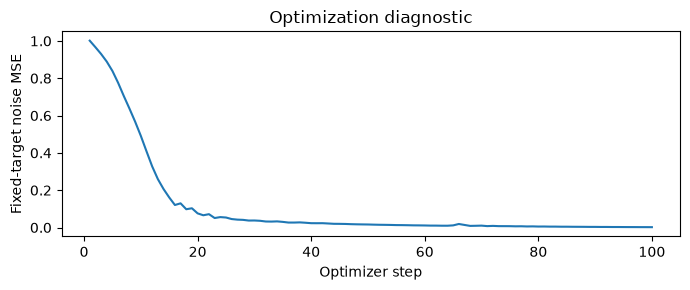

In [21]:
fit_metrics = {"status": "not_run", "reason": "no_approved_pilot_or_budget"}
if pilot_latents is not None and pilot_metrics.get("status") == "pilot_frozen":
    torch.manual_seed(3)
    fixed_clean = pilot_latents[:4].to(DEVICE)
    fixed_noise = torch.randn_like(fixed_clean)
    fixed_t = torch.full((4,), 499, dtype=torch.long, device=DEVICE)
    betas = torch.linspace(0.0001, 0.02, 1000, device=DEVICE)
    abar = (1 - betas).cumprod(0)[499]
    fixed_input = abar.sqrt() * fixed_clean + (1 - abar).sqrt() * fixed_noise
    teaching_model = TeachingDiT(depth=2, hidden=128, heads=4).to(DEVICE)
    fit_metrics = fit_fixed_target(teaching_model, fixed_input, fixed_t, fixed_noise, deadline, 100)
    fit_metrics.update(
        parameters=sum(p.numel() for p in teaching_model.parameters()),
        fixed_time_index=499,
        alpha_bar=abar.item(),
        batch=4,
    )
    torch.save(
        {
            "model": teaching_model.state_dict(),
            "core_source": "notebook_reference",
            "purpose": "fixed_target_diagnostic_only",
        },
        RUN / "teaching_dit_fixed_target.pt",
    )
print({k: v for k, v in fit_metrics.items() if k != "history"})
if fit_metrics.get("history"):
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(
        [r["step"] for r in fit_metrics["history"]], [r["loss"] for r in fit_metrics["history"]]
    )
    ax.set(
        xlabel="Optimizer step", ylabel="Fixed-target noise MSE", title="Optimization diagnostic"
    )
    fig.tight_layout()
    fig.savefig(FIG / "fixed_fit.png", dpi=140)
    plt.show()

### **2. 如何解释成功、失败与下一步**

如果固定监督 MSE 明显下降，说明数据、时间条件、主干、输出和优化器至少形成了可更新链路。如果不降，优先检查张量维度、零初始化梯度阶段、学习率与目标尺度；不要马上增加深度或训练时长。

即使降到很低，也不能推出模型学会真实图标分布。它只见到 4 张固定潜变量、一个时间和固定噪声，没有覆盖新的随机噪声与时间。下一周才加入随机时间训练、完整反向链、EMA 与恢复；再后面才有文本条件及独立条件评测。

本周没有最终生成样本，重建图必须标作“VAE 重建”。检查前向过程时使用的已知真噪声，也不能记作网络能力。

## **十二、论文地图、核心练习与交接**

### **1. 带着问题读四篇核心论文**

资料核验日期：2026-10-28。PDF 统一在 [papers](../papers/README.md)，其版本与哈希在清单中。

| 论文 | 本周读哪里 | 要回答什么 | 对应笔记 |
| --- | --- | --- | --- |
| [DDPM](https://arxiv.org/abs/2006.11239v2) | 第 2–3 节、算法 1/2 | 换成潜变量后，加噪与噪声目标为什么仍成立 | 第七章 |
| [VAE](https://arxiv.org/abs/1312.6114v11) | 第 2–3 节、附录 B/C | 后验均值与随机样本为何不同，KL 并不保证经验标准化 | 第四章，第二周笔记 |
| [LDM](https://arxiv.org/abs/2112.10752v2) | 图 1、第 3.1–3.2 节、第 4.1 节 | 为什么先验证表示，再训练生成主干 | 第二、四、五章 |
| [DiT](https://arxiv.org/abs/2212.09748v2) | 第 3 节、图 3、附录 A | patch、时间调制、零门控、输出头怎样组合 | 第八至十一章 |

DiT 论文首次提交于 2022 年，所读 v2 于 2023 年修订。官方代码参考 [models.py](https://github.com/facebookresearch/DiT/blob/main/models.py)，其仓库已经归档，本项目不直接复用旧环境。原论文类别条件、学习方差和大规模 ImageNet 训练不能算成本项目成果。

当下表示学习与更现代生成目标的前沿入口保留在总规划，先完成本周表示与梯度证据，再研究 REPA/RAE；本周不把论文数量当学习深度。

### **2. 合上参考，独立完成 L03**

按 [L03 任务包](../../learning/L03_DiT核心任务.md) 实现项目 `patchify`、`unpatchify` 与 `DiTBlock`。先手写一个多通道 patch 排列，再完成代码。验收脚本只导入项目接口，未实现就报告待做，不自动从本笔记提取答案。

| 自测问题 | 参考解答 |
| --- | --- |
| 潜变量 4 通道是不是 RGBA？ | 不是，是编码器学习的表示通道，没有固定颜色语义 |
| 为什么缓存后验均值？ | 减少编码随机性以便受控比较；与后验采样不完全等价 |
| 缩放系数会把 16×16 变为别的分辨率吗？ | 不会，只改变数值尺度；空间下采样由网络决定 |
| 两个往返函数互相抵消错误怎么办？ | 加入独立手排顺序与逐索引测试 |
| 为什么 adaLN 不直接使用标准 LN 的固定 affine 参数？ | 调制参数来自条件，可随时间改变；固定 affine 不能承担同样职责 |
| 注意力参数第一步梯度为零是否必然有 bug？ | 不是；零门控和零输出头会分阶段开放梯度，需按预期验证 |
| 96 张重建属性全对证明生成能力吗？ | 不证明；它只检验表示链路和特定诊断子集 |
| 固定监督拟合成功后下一项实验？ | 随机时间与噪声训练、完整采样、独立验证，再判断生成能力 |

学习验收：不看代码画完整数据流；手算一个 patch；解释一个缩放错误；预测零门控的梯度；提出重建已丢对象时的排错顺序。完成答案阅读并不等于已通过脱稿验收。

### **3. 真实结果与阶段状态登记**

In [22]:
# JSON 是本次真实执行记录；计划阈值与实际结果分别保留。
results = {
    "date": "2026-10-28",
    "core_source": "notebook_reference",
    "device": DEVICE,
    "python": platform.python_version(),
    "torch": torch.__version__,
    "cost_yuan": 0,
    "dataset_id": config["dataset_id"],
    "manifest_sha256": hash_file(manifest_path),
    "data_audit": data_audit,
    "raw_parser": raw_metrics,
    "known_corruptions": degraded_metrics,
    "model_identity": adapter.identity,
    "scale": adapter.scale,
    "representation": reconstruction_metrics,
    "representation_gate": representation_passed,
    "scale_roundtrip": {"inverse_max_abs": scale_error, "decode_max_abs": decode_error},
    "pilot_cache": pilot_metrics,
    "gradient_stages": gradient_stages,
    "baseline_parameters": baseline_parameters,
    "fixed_fit": fit_metrics,
    "preflight_seconds": preflight_seconds,
    "prior_notebook_seconds": prior_seconds,
    "notebook_experiment_seconds": walltime.monotonic() - experiment_start,
    "learner_core_verified": False,
    "learner_understanding_verified": False,
    "full_latent_cache_complete": False,
    "generation_performed": False,
    "limitations": [
        "Rule parser limited to controlled icons",
        "Validation stress subset, not unbiased estimate",
        "Single-seed fixed-target fit",
        "No random-time training or reverse generation",
        "No text condition or formal S3 evaluator",
        "S1 learner dependencies remain pending",
    ],
}
result_path = ROOT / "reports/stage2/week3_results.json"
result_path.write_text(json.dumps(results, indent=2, ensure_ascii=False) + "\n")
print(
    {
        "results": str(result_path),
        "representation_gate": representation_passed,
        "pilot_status": pilot_metrics.get("status"),
        "fit_steps": fit_metrics.get("steps", 0),
        "full_generation": False,
        "learner_core": "pending",
    }
)

{'results': '/Users/lucius/projects/personal/MiniGen/reports/stage2/week3_results.json', 'representation_gate': True, 'pilot_status': 'pilot_frozen', 'fit_steps': 100, 'full_generation': False, 'learner_core': 'pending'}


本周交付状态以 [实验报告](../../reports/stage2/week3.md) 为准。S2-01 记录数据与质量证据；S2-02 记录教学表示检查，S1 个人 VAE 前置仍待验收；S2-03 只完成试点；S2-04 提供教学参考和个人任务，不能代替你亲手实现。S2-05、S2-06 留在第四周。

下一步先完成并解释 L01/L02/L03 核心，再连接随机时间训练器。Agent 可以继续维护数据、缓存和工程，但不能静默替换个人核心。